# Customer Personality Analysis

## Project Overview

This project focuses on cleaning, preprocessing, and analyzing customer data using Python and Pandas.

The dataset contains customer demographic information, household details, purchasing behaviour, product spending, shopping channel activity, and marketing campaign responses.

The objective is to investigate data quality, understand customer purchasing patterns, segment customers based on spending, and develop practical business insights that can support data-informed marketing decisions.

### Project Objectives

- Investigate missing, duplicated, inconsistent, and unusual data.
- Clean and preprocess customer records while documenting assumptions.
- Explore spending across product categories and shopping channels.
- Segment customers according to total recorded product spending.
- Examine spending patterns across demographic and household groups.
- Explore website activity, purchase recency, and campaign responses.
- Communicate findings through charts and evidence-based recommendations.

### Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

### Dataset Information

- **Dataset:** Customer Personality Analysis
- **Source:** [Kaggle – Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)
- **Original dimensions:** 2,240 rows and 29 columns
- **Format:** Tab-separated text file (`.csv` extension)

### Project Workflow

1. Load the dataset and inspect its structure.
2. Investigate data quality and unusual values.
3. Clean and preprocess the working copy.
4. Validate the cleaned dataset.
5. Perform exploratory data analysis (EDA).
6. Create visualizations.
7. Summarize business insights, recommendations, and limitations.

> This is a personal learning and portfolio project. The analysis is descriptive and should not be interpreted as proof of causation.

## 1. Importing Libraries and Loading Data

Import the Python libraries used throughout the project. The source dataset is kept unchanged, and a separate working copy will be created during preprocessing.

**Folder assumption:** This notebook is stored in `notebooks/`, while the source file is stored in `data/`.

In [21]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("marketing_campaign.csv", sep="\t")

# Display first five rows
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 2. Initial Data Exploration

The following checks help understand the dataset's dimensions, columns, data types, summary statistics, missing values, and exact duplicate rows.

In [22]:
# Number of rows and columns
df.shape

(2240, 29)

In [23]:
# Column names
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='str')

In [24]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [25]:
# Statistical summary
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [26]:
# Missing values in each column
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [27]:
# Duplicate records
df.duplicated().sum()

np.int64(0)

## 3. Data Quality Investigation

This section investigates categorical values, customer ID uniqueness, unusual birth years, income values, date formats, and potentially similar customer records.

The purpose is to understand questionable records before deciding whether any changes are justified.

In [28]:
print("Education values:")
print(df["Education"].value_counts())

print("\nMarital Status values:")
print(df["Marital_Status"].value_counts())

Education values:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Marital Status values:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [29]:
print("Unique customer IDs:", df["ID"].nunique())

print("Total records:", len(df))

print("Duplicate customer IDs:", df["ID"].duplicated().sum())

Unique customer IDs: 2240
Total records: 2240
Duplicate customer IDs: 0


In [30]:
print("Birth year frequency:")
print(df["Year_Birth"].value_counts().sort_index().head(15))

Birth year frequency:
Year_Birth
1893     1
1899     1
1900     1
1940     1
1941     1
1943     7
1944     7
1945     8
1946    16
1947    16
1948    21
1949    30
1950    29
1951    43
1952    52
Name: count, dtype: int64


In [31]:
print(df[df["Year_Birth"] < 1940][["ID", "Year_Birth"]])

        ID  Year_Birth
192   7829        1900
239  11004        1893
339   1150        1899


In [32]:
print(df["Income"].describe())

print("\nHighest 10 income values:")
print(df.nlargest(10, "Income")[["ID", "Income"]])

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64

Highest 10 income values:
         ID    Income
2233   9432  666666.0
617    1503  162397.0
687    1501  160803.0
1300   5336  157733.0
164    8475  157243.0
1653   4931  157146.0
2132  11181  156924.0
655    5555  153924.0
1898   4619  113734.0
646    4611  105471.0


In [33]:
print(df["Dt_Customer"].head(10))

print("\nUnique date formats / sample values:")
print(df["Dt_Customer"].sample(10, random_state=42))

0    04-09-2012
1    08-03-2014
2    21-08-2013
3    10-02-2014
4    19-01-2014
5    09-09-2013
6    13-11-2012
7    08-05-2013
8    06-06-2013
9    13-03-2014
Name: Dt_Customer, dtype: str

Unique date formats / sample values:
324     11-01-2013
96      22-11-2012
2104    28-02-2013
1259    16-08-2013
1061    25-07-2013
1805    08-06-2013
916     26-12-2013
350     17-12-2013
1901    13-04-2014
1650    26-02-2014
Name: Dt_Customer, dtype: str


In [34]:
unusual_status = ["Alone", "Absurd", "YOLO"]

unusual_customers = df[
    df["Marital_Status"].isin(unusual_status)
]

unusual_customers

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
131,433,1958,Master,Alone,61331.0,1,1,10-03-2013,42,534,...,8,0,0,0,0,0,0,3,11,0
138,7660,1973,PhD,Alone,35860.0,1,1,19-05-2014,37,15,...,5,1,0,0,0,0,0,3,11,1
153,92,1988,Graduation,Alone,34176.0,1,0,12-05-2014,12,5,...,6,0,0,0,0,0,0,3,11,0
2093,7734,1993,Graduation,Absurd,79244.0,0,0,19-12-2012,58,471,...,1,0,0,1,1,0,0,3,11,1
2134,4369,1957,Master,Absurd,65487.0,0,0,10-01-2014,48,240,...,2,0,0,0,0,0,0,3,11,0
2177,492,1973,PhD,YOLO,48432.0,0,1,18-10-2012,3,322,...,8,0,0,0,0,0,0,3,11,0
2202,11133,1973,PhD,YOLO,48432.0,0,1,18-10-2012,3,322,...,8,0,0,0,0,0,0,3,11,1


In [35]:
print("Unusual category counts:")
print(unusual_customers["Marital_Status"].value_counts())

print("\nMissing values in these records:")
print(unusual_customers.isnull().sum())

Unusual category counts:
Marital_Status
Alone     3
Absurd    2
YOLO      2
Name: count, dtype: int64

Missing values in these records:
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64


In [36]:
df[df["ID"].isin([492, 11133])].T

,2177,2202
ID,492,11133
Year_Birth,1973,1973
Education,PhD,PhD
Marital_Status,YOLO,YOLO
Income,48432.0,48432.0
Kidhome,0,0
Teenhome,1,1
Dt_Customer,18-10-2012,18-10-2012
Recency,3,3
MntWines,322,322


In [37]:
comparison_columns = [
    col for col in df.columns
    if col not in ["ID", "Response"]
]

possible_duplicates = df[
    df.duplicated(subset=comparison_columns, keep=False)
]

possible_duplicates

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
8,4855,1974,PhD,Together,30351.0,1,0,06-06-2013,19,14,...,9,0,0,0,0,0,0,3,11,1
15,2114,1946,PhD,Single,82800.0,0,0,24-11-2012,23,1006,...,3,0,0,1,1,0,0,3,11,1
17,4939,1946,Graduation,Together,37760.0,0,0,31-08-2012,20,84,...,7,0,0,0,0,0,0,3,11,0
23,4047,1954,PhD,Married,65324.0,0,1,11-01-2014,0,384,...,4,0,0,0,0,0,0,3,11,0
24,1409,1951,Graduation,Together,40689.0,0,1,18-03-2013,69,270,...,8,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2218,4838,1978,Graduation,Together,22775.0,1,0,19-06-2013,40,5,...,8,0,0,0,0,0,0,3,11,0
2221,7366,1982,Master,Single,75777.0,0,0,04-07-2013,12,712,...,1,0,1,1,0,0,0,3,11,1
2225,4749,1968,Graduation,Together,58554.0,1,1,26-09-2012,55,368,...,7,0,0,0,0,0,0,3,11,0
2234,8372,1974,Graduation,Married,34421.0,1,0,01-07-2013,81,3,...,7,0,0,0,0,0,0,3,11,0


In [38]:
df.loc[df["ID"] == 9432].T

,2233
ID,9432
Year_Birth,1977
Education,Graduation
Marital_Status,Together
Income,666666.0
Kidhome,1
Teenhome,0
Dt_Customer,02-06-2013
Recency,23
MntWines,9


In [39]:
Q1 = df["Income"].quantile(0.25)
Q3 = df["Income"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 35303.0
Q3: 68522.0
IQR: 33219.0
Lower Bound: -14525.5
Upper Bound: 118350.5


In [40]:
income_outliers = df[
    (df["Income"] < lower_bound) |
    (df["Income"] > upper_bound)
]

print("Number of income outliers:", len(income_outliers))

income_outliers[["ID", "Income"]].sort_values(
    by="Income",
    ascending=False
)

Number of income outliers: 8


,ID,Income
2233,9432,666666.0
617,1503,162397.0
687,1501,160803.0
1300,5336,157733.0
164,8475,157243.0
1653,4931,157146.0
2132,11181,156924.0
655,5555,153924.0


In [41]:
date_check = pd.to_datetime(
    df["Dt_Customer"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Invalid dates:", date_check.isna().sum())

Invalid dates: 0


In [42]:
df[df["Year_Birth"] < 1940][
    ["ID", "Year_Birth", "Education", "Marital_Status", "Income"]
]

print("Negative income values:", (df["Income"] < 0).sum())
print("Zero income values:", (df["Income"] == 0).sum())


Negative income values: 0
Zero income values: 0


### Data Quality Investigation Notes

- The dataset contains 2,240 unique customer IDs and no exact duplicate rows.
- `Income` contains 24 missing values.
- The `Education` category `2n Cycle` is retained as provided.
- The unusual marital-status values `Alone`, `Absurd`, and `YOLO` are investigated before being grouped as `Unknown` in this project.
- Three unusually old birth years are flagged for review rather than deleted.
- Eight income values are identified as IQR outliers. They are retained and flagged because an outlier is not automatically an error.
- Similar customer profiles are not automatically treated as duplicate customers. Records are retained unless there is sufficient evidence that they represent duplicate identities.
- The customer date field is checked using the day-month-year format.

## 4. Data Cleaning and Preprocessing

A separate working copy is created so the original DataFrame remains unchanged. The following steps address missing income, unusual marital-status labels, birth-year flags, income outlier flags, and date conversion.

**Important assumptions:** Median imputation and recoding unusual marital-status values are project decisions. They are not confirmed corrections from the dataset publisher.

In [43]:
df_clean = df.copy()

In [44]:
print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

df_clean.head()

Original dataset: (2240, 29)
Working dataset: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [45]:
df_clean["Income"].isnull().sum()


np.int64(24)

In [46]:
income_median = df_clean["Income"].median()

print("Median Income:", income_median)

Median Income: 51381.5


In [47]:
df_clean["Income"] = df_clean["Income"].fillna(income_median)

In [48]:
print("Missing Income values after cleaning:",
      df_clean["Income"].isnull().sum())

print("Total rows:", len(df_clean))

Missing Income values after cleaning: 0
Total rows: 2240


In [49]:
df_clean["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [50]:
df_clean["Marital_Status"].value_counts(normalize=True) * 100

Marital_Status
Married     38.571429
Together    25.892857
Single      21.428571
Divorced    10.357143
Widow        3.437500
Alone        0.133929
Absurd       0.089286
YOLO         0.089286
Name: proportion, dtype: float64

In [51]:
unusual_statuses = ["Alone", "Absurd", "YOLO"]

In [52]:
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace(
    unusual_statuses,
    "Unknown"
)

In [53]:
df_clean["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Unknown       7
Name: count, dtype: int64

In [54]:
print(
    "Unusual categories remaining:",
    df_clean["Marital_Status"].isin(unusual_statuses).sum()
)

Unusual categories remaining: 0


In [55]:
df_clean["Birth_Year_Flag"] = np.where(
    df_clean["Year_Birth"] < 1940,
    "Review",
    "Normal"
)

In [56]:
df_clean["Birth_Year_Flag"].value_counts()

Birth_Year_Flag
Normal    2237
Review       3
Name: count, dtype: int64

In [57]:
df_clean.loc[
    df_clean["Birth_Year_Flag"] == "Review",
    ["ID", "Year_Birth", "Birth_Year_Flag"]
]

,ID,Year_Birth,Birth_Year_Flag
192,7829,1900,Review
239,11004,1893,Review
339,1150,1899,Review


In [58]:
df_clean["Income_Flag"] = np.where(
    (df_clean["Income"] < lower_bound) |
    (df_clean["Income"] > upper_bound),
    "Outlier",
    "Normal"
)

In [59]:
df_clean["Income_Flag"].value_counts()

Income_Flag
Normal     2232
Outlier       8
Name: count, dtype: int64

In [60]:
df_clean.loc[
    df_clean["Income_Flag"] == "Outlier",
    ["ID", "Income", "Income_Flag"]
].sort_values(by="Income", ascending=False)

,ID,Income,Income_Flag
2233,9432,666666.0,Outlier
617,1503,162397.0,Outlier
687,1501,160803.0,Outlier
1300,5336,157733.0,Outlier
164,8475,157243.0,Outlier
1653,4931,157146.0,Outlier
2132,11181,156924.0,Outlier
655,5555,153924.0,Outlier


In [61]:
df_clean["Dt_Customer"].dtype

<StringDtype(storage='python', na_value=nan)>

In [62]:
df_clean["Dt_Customer"] = pd.to_datetime(
    df_clean["Dt_Customer"],
    format="%d-%m-%Y"
)

In [63]:
print("New data type:", df_clean["Dt_Customer"].dtype)
print("Missing dates:", df_clean["Dt_Customer"].isnull().sum())
print(df_clean["Dt_Customer"].head())

New data type: datetime64[us]
Missing dates: 0
0   2012-09-04
1   2014-03-08
2   2013-08-21
3   2014-02-10
4   2014-01-19
Name: Dt_Customer, dtype: datetime64[us]


## 5. Data Validation

After cleaning, validate missing values, data types, dataset dimensions, duplicate rows, and customer ID uniqueness. These checks help confirm that the preprocessing steps produced the expected structure.

In [64]:
df_clean.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
Birth_Year_Flag        0
Income_Flag            0
dtype: int64

In [65]:
df_clean.dtypes

ID                              int64
Year_Birth                      int64
Education                         str
Marital_Status                    str
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[us]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    int64
Complain                        int64
Z_CostContac

In [66]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (2240, 29)
Cleaned shape: (2240, 31)


In [67]:
print("Duplicate rows:", df_clean.duplicated().sum())

print("Duplicate customer IDs:",
      df_clean["ID"].duplicated().sum())

print("Total customers:", len(df_clean))

Duplicate rows: 0
Duplicate customer IDs: 0
Total customers: 2240


## 6. Exploratory Data Analysis (EDA)

This section explores product spending, customer-level total spending, shopping channels, campaign responses, spending segments, and demographic patterns.

### 6.1 Product Category Spending

In [68]:
product_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

In [69]:
product_spending = df_clean[product_columns].sum()

print(product_spending)

MntWines            680816
MntFruits            58917
MntMeatProducts     373968
MntFishProducts      84057
MntSweetProducts     60621
MntGoldProds         98609
dtype: int64


In [70]:
product_spending = product_spending.sort_values(ascending=False)

print(product_spending)

MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64


In [71]:
product_share = (
    product_spending / product_spending.sum()
) * 100

product_share = product_share.round(2)

print(product_share)

MntWines            50.17
MntMeatProducts     27.56
MntGoldProds         7.27
MntFishProducts      6.19
MntSweetProducts     4.47
MntFruits            4.34
dtype: float64


In [72]:
df_clean["Total_Spending"] = df_clean[product_columns].sum(axis=1)

In [73]:
df_clean[["ID", "Total_Spending"]].head()

,ID,Total_Spending
0,5524,1617
1,2174,27
2,4141,776
3,6182,53
4,5324,422


In [74]:
top_customers = df_clean[
    ["ID", "Total_Spending"]
].sort_values(
    by="Total_Spending",
    ascending=False
).head(10)

print(top_customers)

         ID  Total_Spending
1572   5350            2525
1179   5735            2525
1492   1763            2524
987    4580            2486
1052   4475            2440
1601   5453            2352
1458  10133            2349
1288   9010            2346
1301   6024            2302
943    5386            2302


### 6.2 Shopping Channel Analysis

In [75]:
channel_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

channel_purchases = df_clean[channel_columns].sum()

print(channel_purchases)

NumWebPurchases         9150
NumCatalogPurchases     5963
NumStorePurchases      12970
dtype: int64


In [76]:
channel_share = (
    channel_purchases / channel_purchases.sum()
) * 100

channel_share = channel_share.round(2)

print(channel_share)

NumWebPurchases        32.58
NumCatalogPurchases    21.23
NumStorePurchases      46.18
dtype: float64


### 6.3 Marketing Campaign Responses

In [77]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]

campaign_responses = df_clean[campaign_columns].sum()

print(campaign_responses)

AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    163
dtype: int64


In [78]:
response_counts = df_clean["Response"].value_counts()

print(response_counts)

Response
0    1906
1     334
Name: count, dtype: int64


In [79]:
response_percentage = (
    df_clean["Response"].value_counts(normalize=True) * 100
).round(2)

print(response_percentage)

Response
0    85.09
1    14.91
Name: proportion, dtype: float64


### 6.4 Customer Spending Segmentation

Customers are grouped into Low, Medium, and High Spenders using quartiles of `Total_Spending`. The resulting group proportions are therefore influenced by the chosen quartile-based segmentation method.

In [80]:
df_clean["Total_Spending"].describe()

count    2240.000000
mean      605.798214
std       602.249288
min         5.000000
25%        68.750000
50%       396.000000
75%      1045.500000
max      2525.000000
Name: Total_Spending, dtype: float64

In [81]:
q1 = df_clean["Total_Spending"].quantile(0.25)
q3 = df_clean["Total_Spending"].quantile(0.75)

print("Q1:", q1)
print("Q3:", q3)

Q1: 68.75
Q3: 1045.5


In [82]:
conditions = [
    df_clean["Total_Spending"] <= q1,
    df_clean["Total_Spending"] <= q3
]

choices = ["Low Spender", "Medium Spender"]

df_clean["Spending_Segment"] = np.select(
    conditions,
    choices,
    default="High Spender"
)

In [83]:
segment_counts = df_clean["Spending_Segment"].value_counts()

print(segment_counts)

Spending_Segment
Medium Spender    1120
High Spender       560
Low Spender        560
Name: count, dtype: int64


In [84]:
segment_analysis = df_clean.groupby("Spending_Segment").agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean"),
    Median_Income=("Income", "median")
)

print(segment_analysis.round(2))

                  Customer_Count  Average_Spending  Average_Income  \
Spending_Segment                                                     
High Spender                 560           1490.48        75067.79   
Low Spender                  560             39.26        32589.27   
Medium Spender              1120            446.73        50647.43   

                  Median_Income  
Spending_Segment                 
High Spender            75243.5  
Low Spender             30541.5  
Medium Spender          51258.5  


### 6.5 Household, Education, and Marital Status Analysis

In [85]:
household_analysis = df_clean.groupby(
    ["Kidhome", "Teenhome"]
).agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

print(household_analysis)

                  Customer_Count  Average_Spending  Average_Income
Kidhome Teenhome                                                  
0       0                    638           1106.03        65593.31
        1                    625            703.16        57946.06
        2                     30            673.60        57085.17
1       0                    503            186.42        35078.78
        1                    374            215.21        44158.05
        2                     22            474.00        53287.11
2       0                     17            167.41        34586.00
        1                     31            133.10        42441.23


In [86]:
education_analysis = df_clean.groupby("Education").agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

print(education_analysis.sort_values(
    by="Average_Spending",
    ascending=False
))

            Customer_Count  Average_Spending  Average_Income
Education                                                   
PhD                    486            672.41        56096.30
Graduation            1127            619.90        52707.31
Master                 370            611.78        52896.78
2n Cycle               203            496.53        47688.58
Basic                   54             81.80        20306.26


In [87]:
marital_analysis = df_clean.groupby("Marital_Status").agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

print(
    marital_analysis.sort_values(
        by="Average_Spending",
        ascending=False
    )
)

                Customer_Count  Average_Spending  Average_Income
Marital_Status                                                  
Widow                       77            738.82        56415.32
Divorced                   232            610.63        52834.23
Together                   580            608.39        53223.04
Single                     480            606.48        51002.59
Married                    864            590.80        51722.20
Unknown                      7            571.86        53280.29


### 6.6 Age-Based Analysis

Age is estimated using 2014 as the reference year because the dataset provides birth year rather than a full date of birth. Three records with estimated ages above 100 are flagged and excluded from age-group comparisons, but retained in the cleaned dataset.

In [88]:
df_clean["Age"] = 2014 - df_clean["Year_Birth"]

print(df_clean["Age"].describe())

count    2240.000000
mean       45.194196
std        11.984069
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max       121.000000
Name: Age, dtype: float64


In [89]:
print(
    df_clean[["ID", "Year_Birth", "Age"]]
    .sort_values(by="Age", ascending=False)
    .head(10)
)

         ID  Year_Birth  Age
239   11004        1893  121
339    1150        1899  115
192    7829        1900  114
1950   6663        1940   74
424    6932        1941   73
894    8800        1943   71
1923   4994        1943   71
358    6142        1943   71
39     2968        1943   71
1150   1453        1943   71


In [90]:
df_clean["Age_Flag"] = np.where(
    df_clean["Age"] > 100,
    "Review",
    "Valid"
)

print(df_clean["Age_Flag"].value_counts())

Age_Flag
Valid     2237
Review       3
Name: count, dtype: int64


In [91]:
age_df = df_clean[
    df_clean["Age_Flag"] == "Valid"
].copy()

In [92]:
print("Original customers:", len(df_clean))
print("Customers included in age analysis:", len(age_df))

Original customers: 2240
Customers included in age analysis: 2237


In [93]:
bins = [17, 30, 45, 60, 100]

labels = [
    "Young Adults",
    "Adults",
    "Middle-aged Adults",
    "Seniors"
]

age_df["Age_Group"] = pd.cut(
    age_df["Age"],
    bins=bins,
    labels=labels
)

In [94]:
age_analysis = age_df.groupby(
    "Age_Group",
    observed=True
).agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

print(age_analysis)

                    Customer_Count  Average_Spending  Average_Income
Age_Group                                                           
Young Adults                   259            577.00        45283.46
Adults                         976            539.08        49980.48
Middle-aged Adults             736            652.85        55222.56
Seniors                        266            747.97        58945.65


In [95]:
age_product_analysis = age_df.groupby(
    "Age_Group",
    observed=True
)[product_columns].mean().round(2)

print(age_product_analysis)

                    MntWines  MntFruits  MntMeatProducts  MntFishProducts  \
Age_Group                                                                   
Young Adults          243.14      29.42           190.41            38.53   
Adults                263.53      24.19           152.01            34.93   
Middle-aged Adults    346.49      27.21           166.34            38.35   
Seniors               394.15      28.24           200.34            43.76   

                    MntSweetProducts  MntGoldProds  
Age_Group                                           
Young Adults                   30.47         45.04  
Adults                         25.11         39.31  
Middle-aged Adults             27.46         47.01  
Seniors                        29.85         51.63  


### 6.7 Website Activity and Purchase Recency

In [96]:
web_activity = df_clean.groupby("NumWebVisitsMonth").agg(
    Customer_Count=("ID", "count"),
    Average_Web_Purchases=("NumWebPurchases", "mean"),
    Average_Total_Spending=("Total_Spending", "mean")
).round(2)

print(web_activity)

                   Customer_Count  Average_Web_Purchases  \
NumWebVisitsMonth                                          
0                              11                   3.09   
1                             153                   3.65   
2                             202                   4.22   
3                             205                   4.51   
4                             218                   4.49   
5                             281                   4.32   
6                             340                   4.27   
7                             393                   3.64   
8                             342                   3.89   
9                              83                   4.29   
10                              3                   5.33   
13                              1                   1.00   
14                              2                   0.00   
17                              1                   1.00   
19                              2       

In [97]:
recency_analysis = df_clean.groupby(
    pd.cut(
        df_clean["Recency"],
        bins=[-1, 30, 60, 90, 100],
        labels=["0–30 days", "31–60 days", "61–90 days", "91–100 days"]
    )
).agg(
    Customer_Count=("ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Income=("Income", "mean")
).round(2)

print(recency_analysis)

             Customer_Count  Average_Spending  Average_Income
Recency                                                      
0–30 days               724            595.10        53013.11
31–60 days              654            595.78        51352.07
61–90 days              664            625.19        52300.25
91–100 days             198            612.96        52121.00


In [104]:
from pathlib import Path

output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_dir / "cleaned_marketing_campaign.csv",
    index=False
)

df_clean.to_excel(
    output_dir / "cleaned_marketing_campaign.xlsx",
    index=False
)

print("Cleaned datasets exported successfully!")

Cleaned datasets exported successfully!


## 7. Data Visualizations

The following charts communicate the main patterns found during the analysis. Run the cells in order after completing the earlier data preparation and EDA sections.

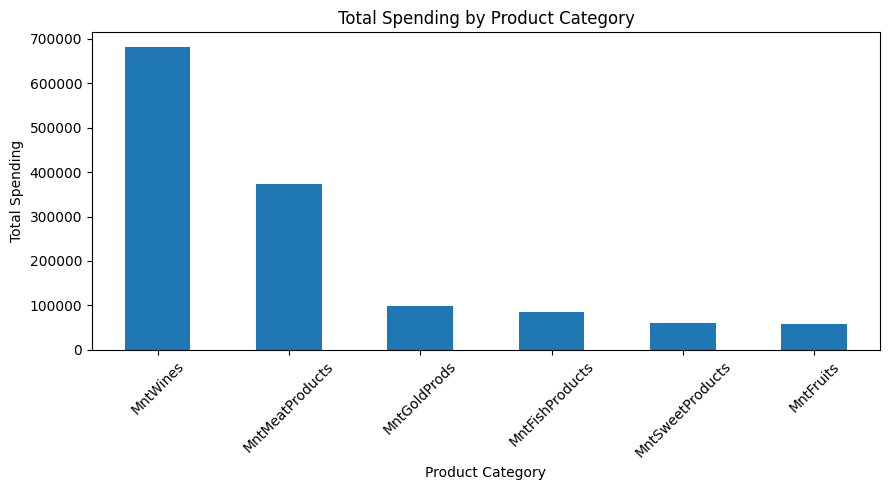

In [98]:
import matplotlib.pyplot as plt

product_spending.plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Spending by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7.1 Total Spending by Product Category

Wines represent the largest share of total recorded product spending, followed by meat products. Together, these categories account for approximately 77.73% of the recorded spending total.

Interpretation: Wines account for the largest share of total recorded customer spending (50.17%), followed by meat products (27.56%). Together, these two categories contribute approximately 77.73% of total spending.

Business insight: The business could prioritize wine and meat inventory planning and explore targeted promotions for these categories.

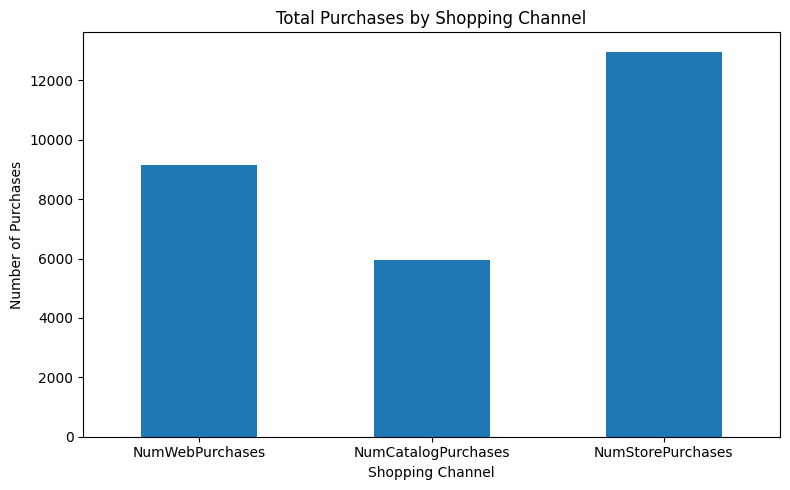

In [99]:
channel_purchases.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Purchases by Shopping Channel"
)

plt.xlabel("Shopping Channel")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Shopping Channel Analysis

A bar chart was created to compare the total number of purchases across web, catalogue, and physical store channels.

**Key Findings:**
- Store purchases recorded the highest count (12,970), representing 46.18% of total purchases.
- Web purchases ranked second (9,150), representing 32.58%.
- Catalogue purchases recorded the lowest count (5,963), representing 21.23%.

**Business Insight:**
Physical stores remain the leading shopping channel in this dataset. However, the business should also consider improving its online shopping experience, as web purchases represent a substantial share of recorded transactions.

**Limitation:** These figures represent purchase counts, not revenue, unique customers, or channel profitability.

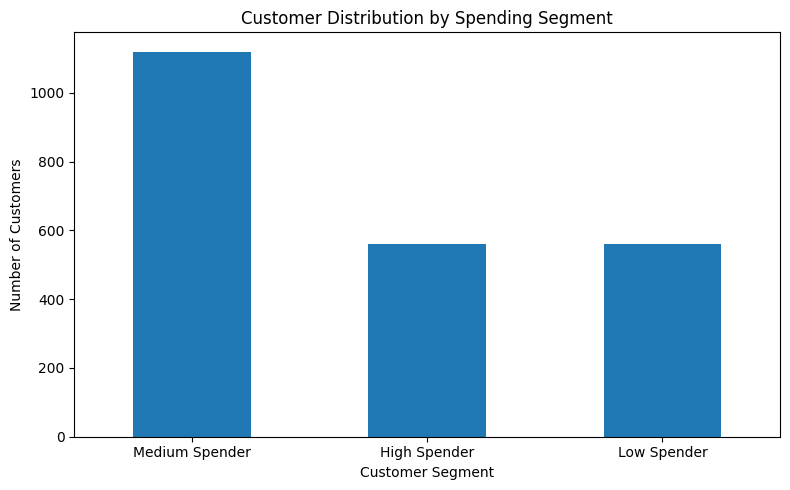

In [100]:
segment_counts = df_clean["Spending_Segment"].value_counts()

segment_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Distribution by Spending Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Customer Distribution by Spending Segment

A bar chart was created to visualize the distribution of customers across Low, Medium, and High Spending segments.

**Key Findings:**
- Medium Spenders represent 1,120 customers (50%).
- High Spenders represent 560 customers (25%).
- Low Spenders represent 560 customers (25%).

**Business Insight:**
The business has a substantial medium-spending customer segment. It could explore targeted offers, product recommendations, and loyalty incentives to encourage increased purchasing activity.

**Limitation:** These segments were created using spending quartiles, so the 50% and 25% distribution is a result of the chosen segmentation method, not an independently discovered customer behaviour pattern.

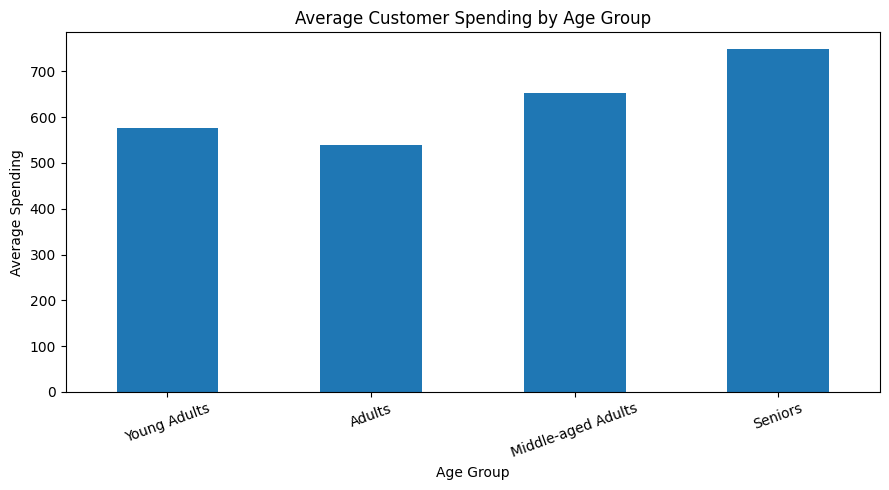

In [101]:
age_spending = age_df.groupby(
    "Age_Group",
    observed=True
)["Total_Spending"].mean()

age_spending.plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Customer Spending by Age Group"
)

plt.xlabel("Age Group")
plt.ylabel("Average Spending")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Average Customer Spending by Age Group

A bar chart was created to compare average customer spending across four age groups.

**Key Findings:**
- Seniors have the highest average spending (747.97).
- Middle-aged Adults rank second (652.85).
- Young Adults have an average spending of 577.00.
- Adults have the lowest average spending (539.08).

**Business Insight:**
Older customer segments demonstrate higher average spending in this dataset. The business could explore targeted product recommendations and loyalty campaigns for Seniors and Middle-aged Adults.

**Limitation:** The three unusually old birth-year records were excluded from this age-based analysis. The results show an association between age group and spending, not causation.

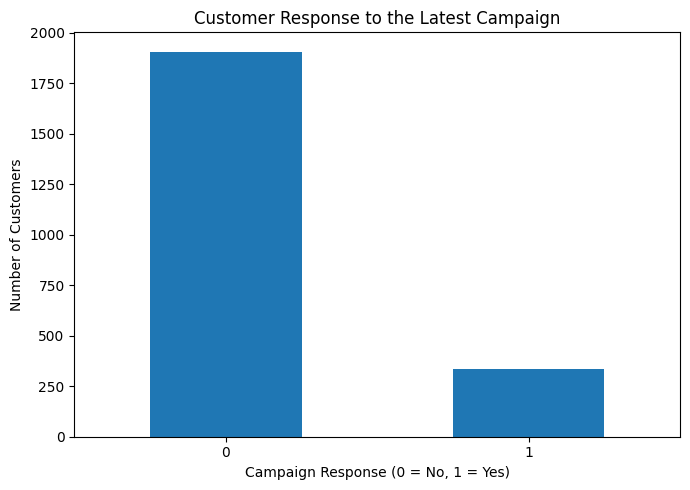

In [102]:
response_counts = df_clean["Response"].value_counts().sort_index()

response_counts.plot(
    kind="bar",
    figsize=(7, 5),
    title="Customer Response to the Latest Campaign"
)

plt.xlabel("Campaign Response (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Customer Response to the Latest Marketing Campaign

A bar chart was created to compare customers who accepted and did not accept the latest marketing campaign.

**Key Findings:**
- 1,906 customers (85.09%) did not accept the campaign.
- 334 customers (14.91%) accepted the campaign.
- The acceptance rate was relatively low compared with the non-response rate.

**Business Insight:**
The business could investigate customer preferences, purchasing behaviour, and previous campaign interactions to develop more relevant marketing offers and improve future campaign responses.

**Limitation:** This analysis describes responses in the available dataset. It does not establish why customers rejected the campaign or prove that a particular marketing strategy would improve acceptance.

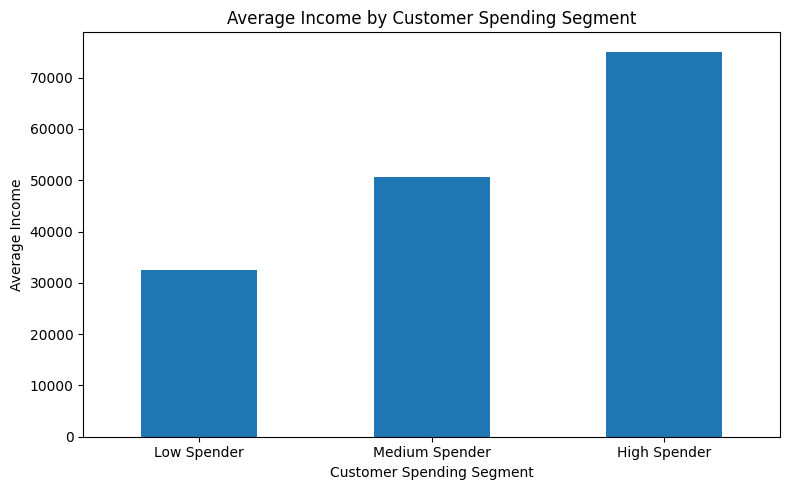

In [103]:
segment_income = df_clean.groupby(
    "Spending_Segment"
)["Income"].mean().reindex(
    ["Low Spender", "Medium Spender", "High Spender"]
)

segment_income.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Income by Customer Spending Segment"
)

plt.xlabel("Customer Spending Segment")
plt.ylabel("Average Income")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Average Income by Customer Spending Segment

A bar chart was created to compare the average income of Low, Medium, and High Spenders.

**Key Findings:**
- High Spenders have the highest average income (75,067.79).
- Medium Spenders have an average income of 50,647.43.
- Low Spenders have the lowest average income (32,589.27).

**Business Insight:**
Customers with higher incomes tend to have higher spending in this dataset. The business could consider income-related customer segmentation when designing product recommendations and marketing campaigns.

**Limitation:** Higher income and higher spending are associated in this dataset, but this does not establish that income directly causes higher spending.

## 8. Key Business Insights and Recommendations

### Product Categories
Wines account for the largest share of recorded product spending, followed by meat products. The business could consider these categories when planning inventory and targeted promotions. Spending totals do not measure profit margins.

### Shopping Channels
Physical stores account for the largest number of recorded purchases, followed by web and catalogue purchases. The online channel remains substantial and may merit continued investment. Purchase counts are not channel revenue or unique-customer counts.

### Customer Spending Segments
The High Spender segment has the highest average income, while the Medium Spender segment contains the largest number of customers. Since the segments were defined using quartiles, their proportions reflect the segmentation rule.

### Age Groups
Seniors have the highest average total spending among the age groups analyzed. This is an association, not evidence that age causes higher spending. Three unusually old records were excluded from age-group comparisons.

### Marketing Campaign
334 customers (14.91%) accepted the latest campaign, while 1,906 (85.09%) did not. Further investigation of customer preferences, campaign targeting, and eligibility would be needed to explain the response rate.

### Website Activity and Recency
Website visits do not show a simple, consistently increasing relationship with web purchases. Average spending is also relatively similar across the recency groups. These patterns should be investigated with additional customer-level and conversion data before making strong decisions.

## 9. Conclusion

This project applied Python, Pandas, and NumPy to investigate and preprocess a customer personality dataset containing 2,240 records. The analysis explored product spending, shopping channels, campaign responses, spending segments, demographic patterns, website activity, and purchase recency.

The strongest descriptive findings were that wines and meat products account for most recorded product spending, physical stores have the highest purchase count, and the Senior age group has the highest average spending among the age groups analyzed.

The project also demonstrates the importance of documenting assumptions, retaining unusual values when they cannot be confirmed as errors, validating cleaning operations, and interpreting business results cautiously.

## 10. Limitations and Assumptions

- Missing income values were filled using the median income. Imputed values are estimates, not the customers' actual incomes.
- `Alone`, `Absurd`, and `YOLO` marital-status values were grouped as `Unknown` for this project; the original meaning of these labels was not verified.
- Income outliers and unusual birth years were flagged rather than deleted.
- Age was estimated using 2014 as a reference year.
- Age-based analysis excluded three records with estimated ages above 100.
- Spending segments were created using quartiles of total product spending.
- Spending amounts do not indicate profit, and purchase counts do not indicate revenue.
- Descriptive associations do not establish causation.
- Dataset redistribution must comply with the licence and terms shown on the original Kaggle dataset page.

## Reproducibility

Install the required libraries using the project's `requirements.txt` file, place the source dataset in the `data/` folder, and run this notebook from the `notebooks/` folder in sequential order.